**NAME - RUCHITA PANKAJ BODKE**\
**PRN - 202401110022**\
**BRANCH - CSE-AIML**\
**BATCH - A2**\
**COURSE - GENERATIVE AI**

# Assignment–02: Comparative Study and Practical Analysis of Generative AI Models


# **Objective**

The objective of this assignment is to compare four generative AI models: Autoencoder (AE), Variational Autoencoder (VAE), Deep Convolutional GAN (DCGAN), and a pretrained Diffusion Model. We study how AE and VAE reconstruct input images, and how DCGAN and Diffusion Models generate new images. We compare their working principles, architectures, strengths, limitations, applications, and output quality.

Device: cuda


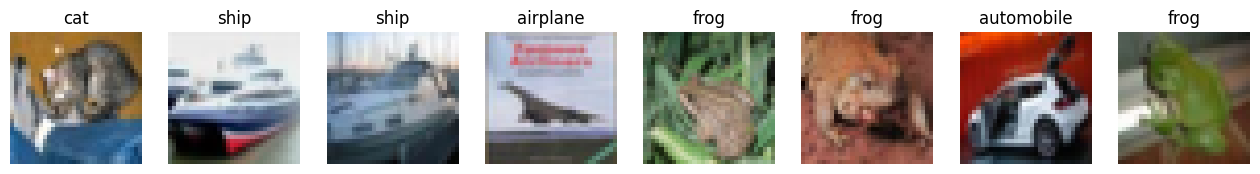

In [6]:
# Import PyTorch, torchvision, and plotting tools.import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Use the GPU when Colab provides one; otherwise run on the CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Convert each PIL image into a PyTorch tensor with values from 0 to 1.
transform = transforms.ToTensor()

# Download CIFAR-10 and create training and test datasets.
# The test set is used later to compare original images with reconstructions.
train_data = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
test_data = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

# Create batches of images for training and evaluation.
train_loader = torch.utils.data.DataLoader(
    train_data, batch_size=128, shuffle=True, num_workers=2
)
test_loader = torch.utils.data.DataLoader(
    test_data, batch_size=128, shuffle=False, num_workers=2
)

# CIFAR-10 class names are used as labels in the image preview.
classes = train_data.classes

# Display a row of images, optionally adding a title above each image.
def show_images(images, titles=None, n=8):
    images = images[:n].cpu()
    fig, axes = plt.subplots(1, len(images), figsize=(2 * len(images), 2))
    for i, ax in enumerate(axes):
      # Change channel order from PyTorch (C, H, W) to Matplotlib (H, W, C).
        ax.imshow(images[i].permute(1, 2, 0).clamp(0, 1))
        ax.axis("off")
        if titles:
            ax.set_title(titles[i])
    plt.show()

# Select a batch of test images and display the first eight.
images, labels = next(iter(test_loader))
show_images(images, [classes[i] for i in labels], n=8)

CIFAR-10 was used as the image dataset for the reconstruction and DCGAN experiments. It contains 32 × 32 color images from ten object categories.The same test images were used for AE and VAE reconstruction comparisons.        

# **Activity A: Autoencoder reconstruction**

An Autoencoder compresses an image into a smaller latent representation and then decodes that representation to reconstruct the input.

Epoch 1/10, loss=0.0165
Epoch 2/10, loss=0.0066
Epoch 3/10, loss=0.0047
Epoch 4/10, loss=0.0039
Epoch 5/10, loss=0.0034
Epoch 6/10, loss=0.0031
Epoch 7/10, loss=0.0028
Epoch 8/10, loss=0.0026
Epoch 9/10, loss=0.0023
Epoch 10/10, loss=0.0022


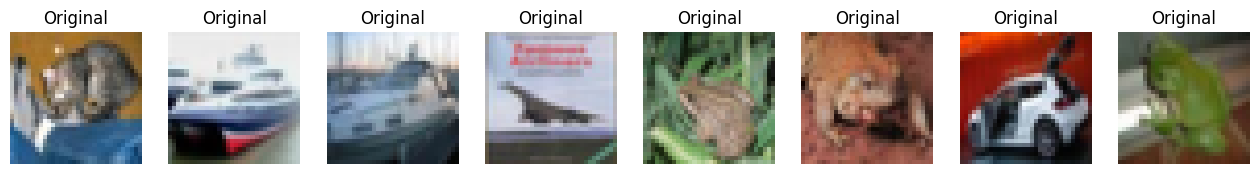

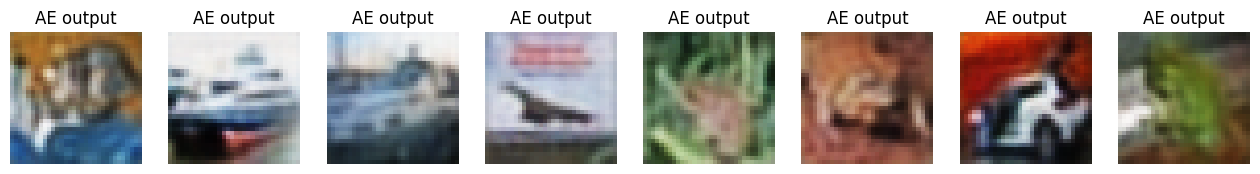

In [9]:
import torch.nn as nn

# The encoder compresses an image; the decoder reconstructs it.
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Each convolution reduces the image's width and height.
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(),   # 32x32 -> 16x16
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),  # 16x16 -> 8x8
            nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(), # 8x8 -> 4x4
        )

        # Transposed convolutions increase the spatial size back to 32x32.
        # Sigmoid keeps reconstructed pixel values between 0 and 1.
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid(),
        )

    def forward(self, x):
      # Pass the input through the encoder and then the decoder.
        return self.decoder(self.encoder(x))

# Create the model and move it to the selected device.
ae = Autoencoder().to(device)

# Mean squared error measures the pixel difference between input and output.
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)

# Train the Autoencoder to reconstruct its input images.
def train_reconstructor(model, epochs=10):
    model.train()
    for epoch in range(epochs):
        total = 0
        for x, _ in train_loader:
            x = x.to(device)

            # Clear gradients from the previous training step.
            optimizer.zero_grad()

            # Reconstruct each input batch and calculate its error.
            output = model(x)
            loss = criterion(output, x)

            # Backpropagate the error and update model parameters.
            loss.backward()
            optimizer.step()
            total += loss.item() * x.size(0)

        # Print the average reconstruction loss for this epoch.
        print(f"Epoch {epoch+1}/{epochs}, loss={total/len(train_data):.4f}")

train_reconstructor(ae, epochs=10)

# Turn off training-specific behavior and reconstruct test images.
ae.eval()
with torch.no_grad():
    sample = images[:8].to(device)
    ae_output = ae(sample)

# Display original inputs and their AE reconstructions.
show_images(sample, ["Original"] * 8)
show_images(ae_output, ["AE output"] * 8)

The Autoencoder was trained to reproduce its input images. Its encoder reduces each image to a compact feature representation, and its decoder uses that representation to reconstruct the image. The output generally preserves the broad shape and color of the input, but fine details may be blurred or lost because the image is compressed into a limited representation.

# **Activity A: VAE reconstruction**

A VAE learns a probability distribution for the latent representation instead of encoding each image as one fixed point. It samples from that representation, which supports both reconstruction and new image generation.

Epoch 1/10, loss=1921.08
Epoch 2/10, loss=1847.93
Epoch 3/10, loss=1835.42
Epoch 4/10, loss=1830.26
Epoch 5/10, loss=1826.80
Epoch 6/10, loss=1824.66
Epoch 7/10, loss=1823.38
Epoch 8/10, loss=1822.65
Epoch 9/10, loss=1821.54
Epoch 10/10, loss=1820.81


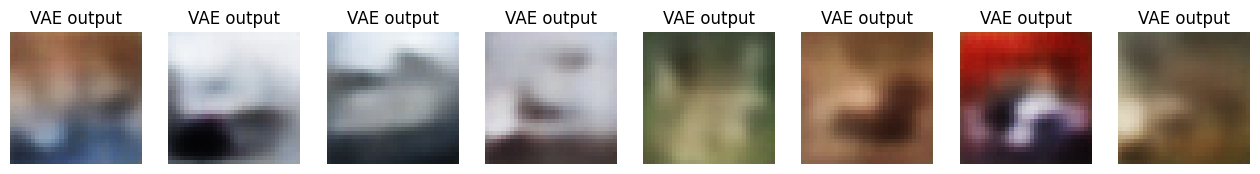

In [10]:
# The VAE encoder predicts a mean and log-variance for each latent vector.
class VAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.latent_dim = latent_dim

        # Extract image features and flatten them into a vector.
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(),
            nn.Flatten()
        )

        # Predict the parameters of the latent probability distribution.
        self.fc_mu = nn.Linear(128 * 4 * 4, latent_dim)
        self.fc_logvar = nn.Linear(128 * 4 * 4, latent_dim)

        # Map a latent vector back to the feature map expected by the decoder.
        self.fc_decode = nn.Linear(latent_dim, 128 * 4 * 4)

        # Upsample the feature map to reconstruct a 32x32 RGB image.
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid()
        )

    def encode(self, x):
        # Return the mean and log-variance of the latent distribution.
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        # Sample a latent vector while allowing gradients to flow through mu/logvar.
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def decode(self, z):
        # Reshape the latent projection into a feature map and reconstruct an image.
        h = self.fc_decode(z).view(-1, 128, 4, 4)
        return self.decoder(h)

    def forward(self, x):
        # Encode, sample a latent vector, and decode it.
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

vae = VAE().to(device)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

# Combine pixel reconstruction error with KL divergence.
# KL divergence encourages latent distributions to remain close to a standard normal.
def vae_loss(recon, x, mu, logvar):
    reconstruction = nn.functional.binary_cross_entropy(recon, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (reconstruction + kl) / x.size(0)

# Train the VAE using its combined reconstruction and KL-divergence loss.
def train_vae(epochs=10):
    vae.train()
    for epoch in range(epochs):
        total = 0
        for x, _ in train_loader:
            x = x.to(device)
            vae_optimizer.zero_grad()

            # The VAE returns the reconstruction and latent distribution parameters.
            recon, mu, logvar = vae(x)
            loss = vae_loss(recon, x, mu, logvar)
            loss.backward()
            vae_optimizer.step()
            total += loss.item() * x.size(0)
        print(f"Epoch {epoch+1}/{epochs}, loss={total/len(train_data):.2f}")

train_vae(epochs=10)

# Reconstruct the same test images used for the AE comparison.
vae.eval()
with torch.no_grad():
    vae_output, _, _ = vae(sample)

show_images(vae_output, ["VAE output"] * 8)

The VAE was trained using a reconstruction loss and a KL-divergence term. The reconstruction loss encourages the output to resemble the input, while the KL term encourages latent representations to follow a regular distribution. In this short run, VAE reconstructions may appear smoother or blurrier than the AE outputs. The stochastic latent sampling can introduce variation, while also making exact image details less consistent.

# **Activity B: DCGAN image generation**

A DCGAN uses two networks: a generator that creates images from random noise, and a discriminator that tries to distinguish generated images from real training images. They train against each other. The short training run below is for demonstration; output quality improves with longer training and a GPU.

Epoch 1/10, D loss=0.933, G loss=5.631
Epoch 2/10, D loss=0.490, G loss=2.928
Epoch 3/10, D loss=0.564, G loss=3.199
Epoch 4/10, D loss=0.431, G loss=2.650
Epoch 5/10, D loss=0.506, G loss=3.422
Epoch 6/10, D loss=0.420, G loss=3.207
Epoch 7/10, D loss=0.552, G loss=1.559
Epoch 8/10, D loss=1.159, G loss=0.132
Epoch 9/10, D loss=0.437, G loss=2.793
Epoch 10/10, D loss=0.290, G loss=3.467


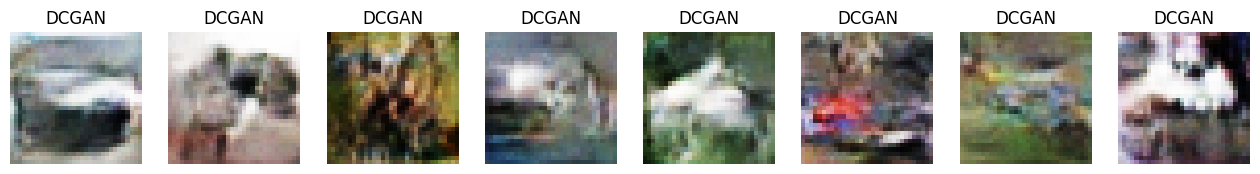

In [11]:
from torchvision.utils import make_grid

# The generator maps random noise to a 32x32 RGB image.
class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            # Start with a small feature map and progressively upsample it.
            nn.ConvTranspose2d(z_dim, 256, 4, 1, 0, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),

            # Tanh produces pixel values in the range [-1, 1].
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)

# The discriminator estimates whether each image is real or generated.
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.LeakyReLU(0.2),

            # Sigmoid converts the final score into a probability.
            nn.Conv2d(256, 1, 4, 1, 0), nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x).view(-1)

z_dim = 100
G = Generator(z_dim).to(device)
D = Discriminator().to(device)
gan_loss = nn.BCELoss()
g_opt = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
d_opt = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

# Normalize real images to [-1, 1] to match the generator's Tanh output.
gan_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Load CIFAR-10 again using the normalization needed by the GAN.
gan_data = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=gan_transform
)
gan_loader = torch.utils.data.DataLoader(
    gan_data, batch_size=128, shuffle=True, num_workers=2
)

# Reuse fixed noise after training to compare generated samples consistently.
fixed_noise = torch.randn(16, z_dim, 1, 1, device=device)

def train_dcgan(epochs=10):
    for epoch in range(epochs):
        for real, _ in gan_loader:
            real = real.to(device)
            b = real.size(0)
            real_targets = torch.ones(b, device=device)
            fake_targets = torch.zeros(b, device=device)

            # Generate fake images and train D to classify real as 1 and fake as 0.
            noise = torch.randn(b, z_dim, 1, 1, device=device)
            fake = G(noise)
            d_opt.zero_grad()
            d_loss = gan_loss(D(real), real_targets) + gan_loss(D(fake.detach()), fake_targets)
            d_loss.backward()
            d_opt.step()

            # Train G to make generated images classified as real by D.
            noise = torch.randn(b, z_dim, 1, 1, device=device)
            fake = G(noise)
            g_opt.zero_grad()
            g_loss = gan_loss(D(fake), real_targets)
            g_loss.backward()
            g_opt.step()

        print(f"Epoch {epoch+1}/{epochs}, D loss={d_loss.item():.3f}, G loss={g_loss.item():.3f}")

train_dcgan(epochs=10)

# Generate a fixed set of samples and convert pixels from [-1, 1] to [0, 1].
G.eval()
with torch.no_grad():
    generated = G(fixed_noise).cpu()
generated = (generated + 1) / 2

show_images(generated, ["DCGAN"] * 16, n=8)

The DCGAN generator learned to create small images from random noise, while the discriminator learned to classify images as real or generated. After a short training run, generated images may be recognizable only as rough colors or shapes. DCGAN quality depends on training stability and data; it can also suffer from mode collapse, where generated images lack variety.

# **Activity B: Pretrained Diffusion Model**

This cell uses the pretrained runwayml/stable-diffusion-v1-5 model.

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

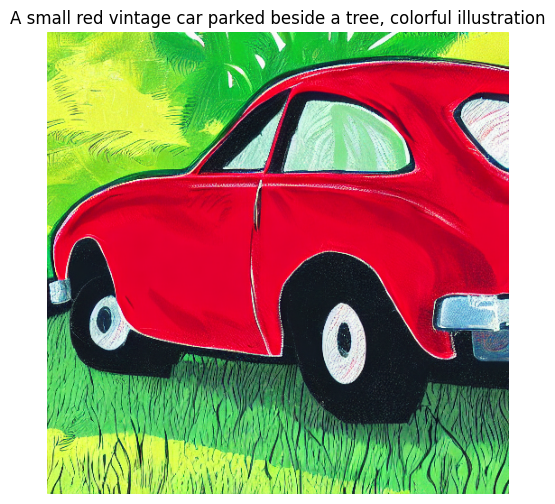

In [12]:
# Install the Diffusers library and its model-loading dependencies in Colab.
!pip -q install diffusers transformers accelerate safetensors

import torch
from diffusers import StableDiffusionPipeline

# Choose the pretrained text-to-image model to load.
model_id = "runwayml/stable-diffusion-v1-5"

# Load the pretrained pipeline.
# The default safety checker is kept enabled.
pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

# Move the pipeline to GPU when available.
pipe = pipe.to("cuda" if torch.cuda.is_available() else "cpu")

# The prompt guides the model toward the requested image content.
prompt = "A small red vintage car parked beside a tree, colorful illustration"

# Generate one image using 25 denoising steps.
# Guidance scale controls how strongly the model follows the prompt.
result = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

# Display the generated image with its prompt for reference.
plt.figure(figsize=(6, 6))
plt.imshow(result)
plt.axis("off")
plt.title(prompt)
plt.show()

The pretrained Diffusion Model generated an image from a text prompt. Diffusion models start from noise and gradually refine it into an image, guided by learned patterns and the prompt. In this experiment, the generated image can contain more detail and visual coherence than the short-run DCGAN outputs. Its output depends on the prompt, model, and settings; it may not represent every prompt detail accurately.

**Conclusion**

This assignment helped me compare image reconstruction using Autoencoders and Variational Autoencoders with image generation using DCGANs and Diffusion Models. Through the practical experiments, I observed how each model produces different results and learned that output quality depends on the model, training, and input.